In [1]:
from calculate import simulate_bets, simulate_sbs
from lvix.preparation import BETS
from lvix.schedule import get_schedule
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (40,20)
plt.rcParams['figure.constrained_layout.use'] = True

In [2]:
sims = 100000

In [3]:
# Chances to win the Super Bowl for each Team by Vegas Odds
schedule = get_schedule()
schedule.normalize_sb_odds()
schedule.print_sb_odds()

Team	%SB
*****	*****
DET	0.22
KC	0.19
BAL	0.13
BUF	0.12
PHI	0.11
MIN	0.05
GB	0.04
TB	0.03
LAC	0.03
LA	0.02
WAS	0.02
DEN	0.01
HOU	0.01
PIT	0.01


In [11]:
# Prepare ourselvs by simulating path to Super Bowl
simulate_sbs(get_schedule, sims)

Team	SBs	Ws	pSB%	aSB%
*****	*****	*****	*****	*****
DET	37667	188152	21.85	37.67
KC	30810	176332	19.36	30.81
BAL	9803	173767	12.58	9.8
BUF	9299	168443	12.33	9.3
PHI	9017	159409	11.08	9.02
MIN	1760	102874	5.25	1.76
GB	513	34012	4.11	0.51
TB	490	81000	3.04	0.49
LAC	373	86757	2.93	0.37
LA	137	38777	2.34	0.14
WAS	117	45477	1.94	0.12
HOU	7	27779	1.03	0.01
DEN	5	9341	1.18	0.01
PIT	2	7880	0.98	0.0


In [5]:
# Compare our prepeared bets against some baseline
from lvix.preparation import BETS
simulate_bets(BETS, get_schedule, sims)

Team	Mean	Median	std	max	min	q60	q80
*****	*****	*****	*****	*****	*****	*****	*****
Reto	132.1	134.0	8.89	146	66	136.0	140.0
Daniele	130.25	134.0	12.64	151	54	136.0	141.0
Silli	133.42	135.0	9.51	147	53	137.0	141.0
Raffael	129.87	131.0	10.78	148	46	134.0	139.0
Mago	118.14	119.0	12.06	146	44	123.0	128.0
Luca	128.51	130.0	11.08	150	49	133.0	138.0
Linus	132.59	135.0	11.01	151	58	137.0	141.0
Jere	128.07	130.0	11.97	149	39	133.0	138.0
Basil	131.35	134.0	11.54	150	41	136.0	141.0
Suler	126.39	129.0	13.22	147	46	133.0	138.0
Seve	131.08	133.0	11.51	152	68	136.0	141.0
Jan	128.42	132.0	13.34	152	38	135.0	139.0
FZN	125.06	129.0	14.5	152	46	132.0	138.0
Jac	105.51	103.0	17.22	160	49	109.0	120.0
Fabio	128.63	130.0	11.55	147	53	133.0	138.0
Severin	126.67	130.0	13.91	149	52	133.0	139.0
Polle	132.78	135.0	9.3	148	56	137.0	141.0


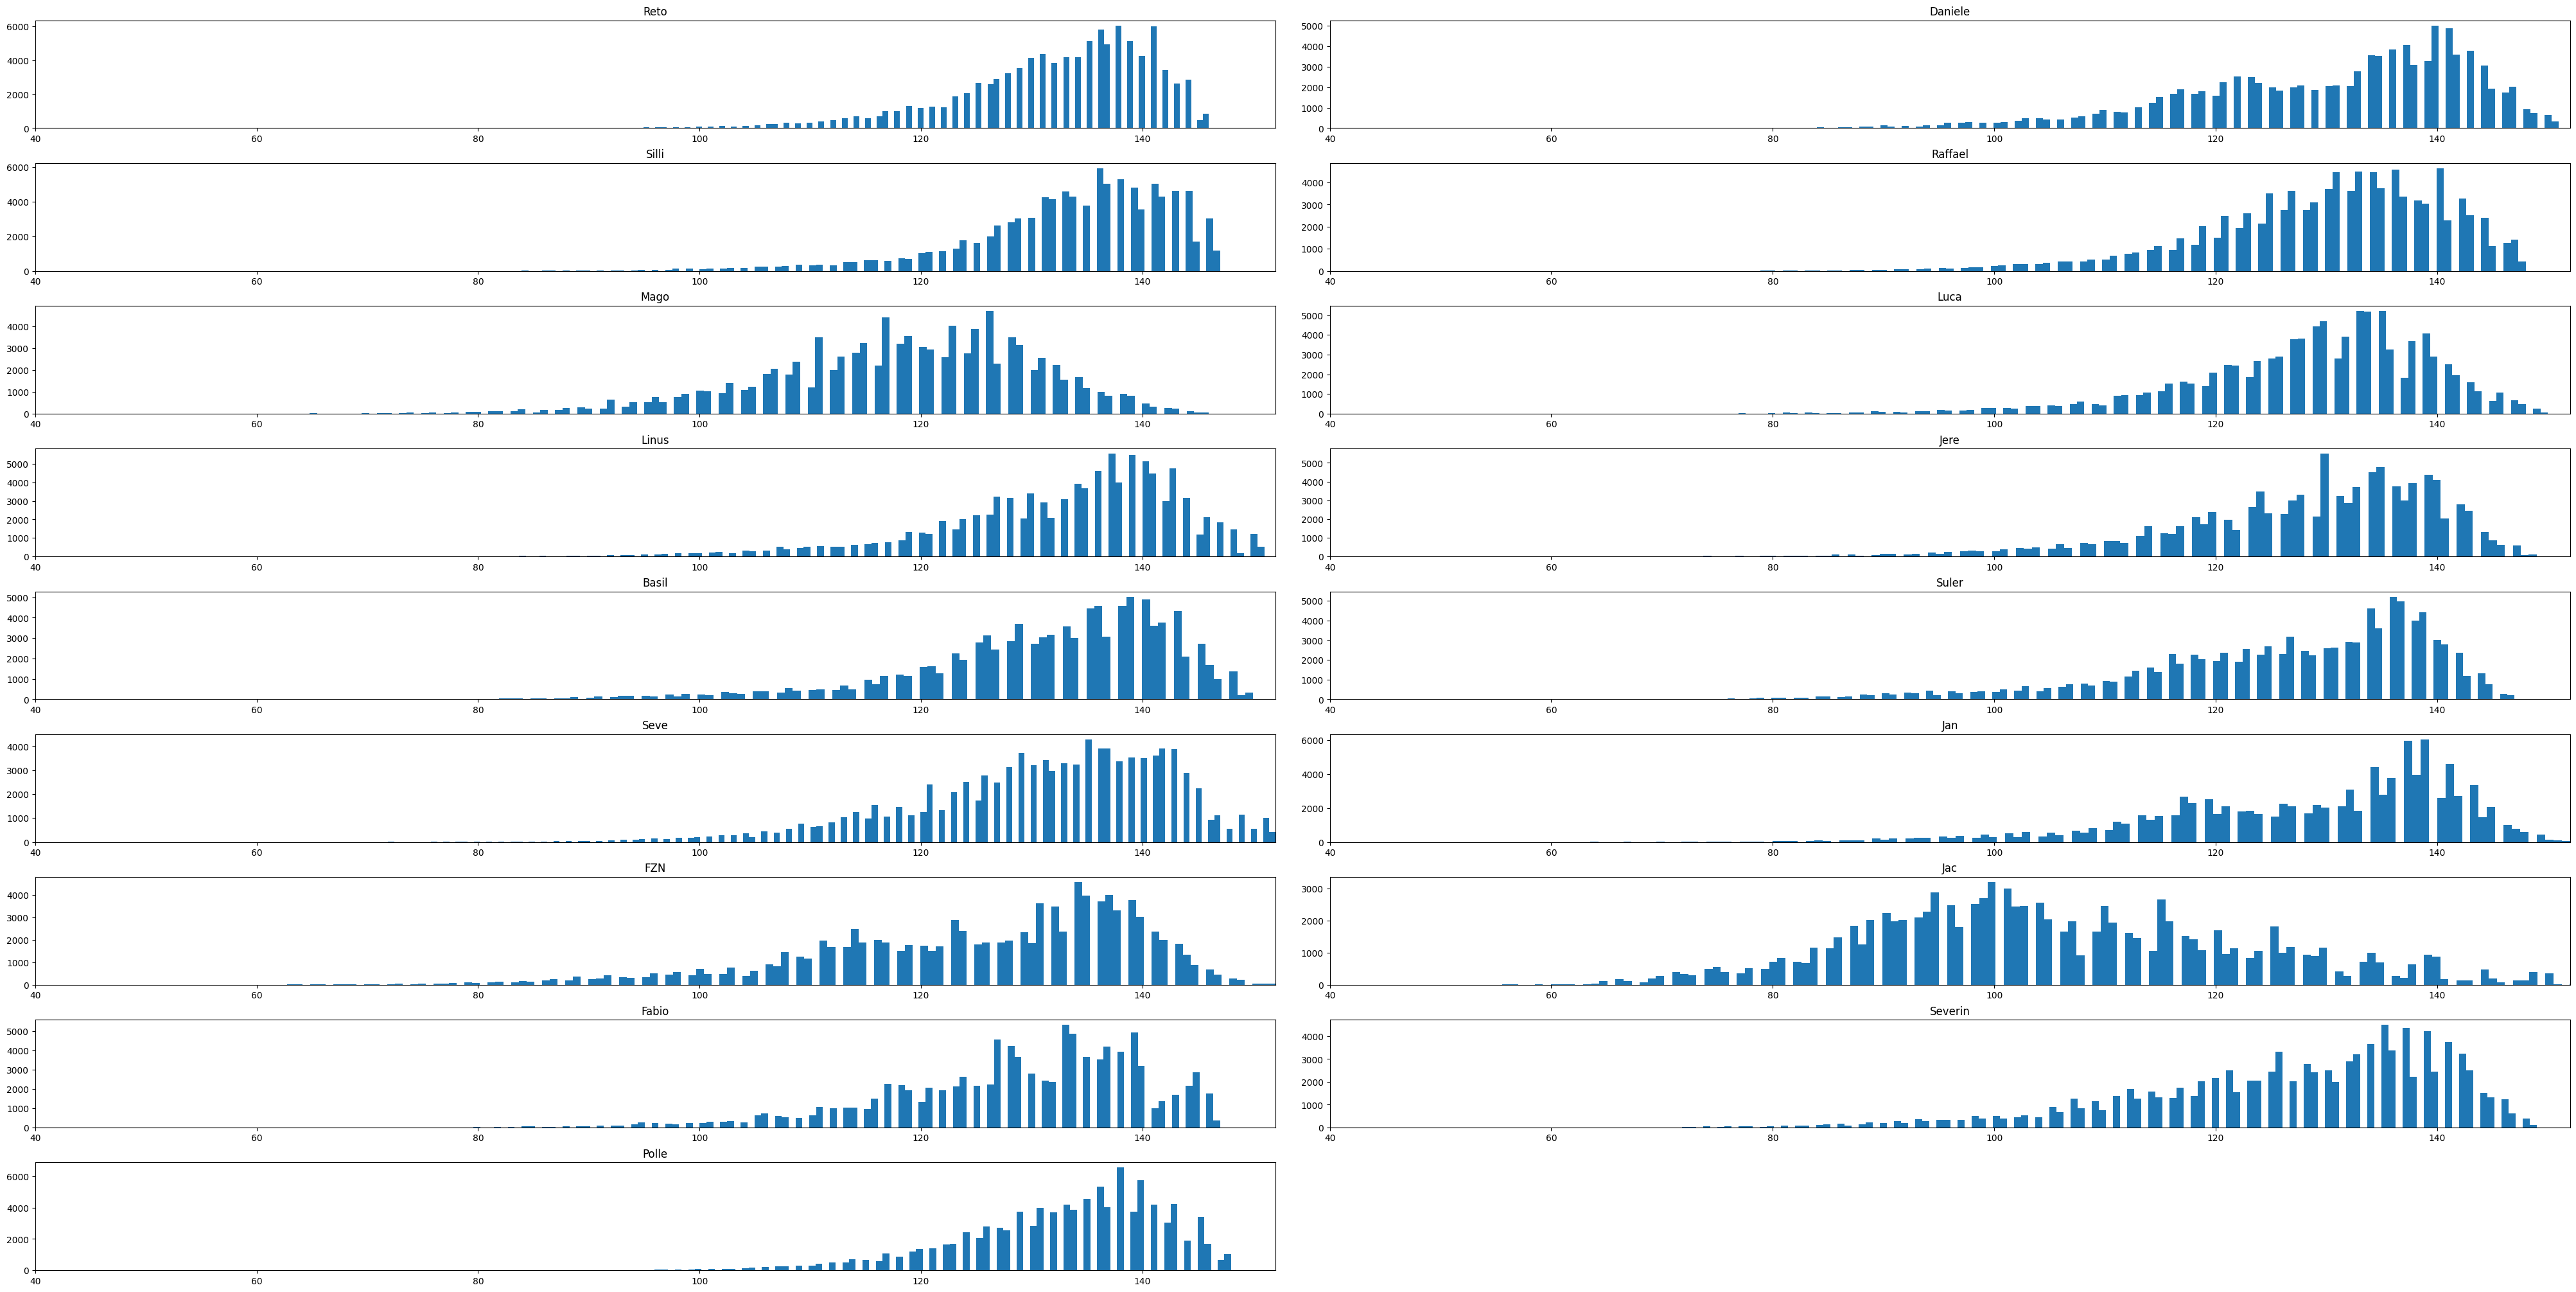

In [6]:
from lvix.game import BETS, get_sb_odds
simulate_bets(BETS, get_schedule, sims)

In [7]:
simulate_sbs(get_schedule, sims, odds=get_sb_odds())

Team	SBs	Ws	pSB%	aSB%
*****	*****	*****	*****	*****
DET	21782	130705	11.6	21.78
KC	19704	127117	10.64	19.7
BUF	14076	169054	11.15	14.08
PHI	13753	163193	11.04	13.75
BAL	11966	149717	10.92	11.97
MIN	5249	105403	7.45	5.25
TB	3908	91473	6.72	3.91
LAC	2592	78567	5.77	2.59
HOU	2296	74019	5.43	2.3
WAS	2212	69240	5.49	2.21
LA	1336	56829	4.65	1.34
GB	535	31932	3.47	0.53
PIT	465	32878	3.47	0.46
DEN	126	19873	2.18	0.13


Team	Mean	Median	std	max	min	q60	q80
*****	*****	*****	*****	*****	*****	*****	*****
Reto	120.57	123.0	14.54	146	45	127.0	133.0
Daniele	122.1	124.0	15.99	151	36	128.0	137.0
Silli	121.34	124.0	14.53	147	40	127.0	134.0
Raffael	119.12	121.0	14.99	148	40	125.0	132.0
Mago	108.46	110.0	16.83	146	39	115.0	123.0
Luca	120.26	123.0	14.81	150	44	126.0	133.0
Linus	122.86	125.0	15.35	151	38	129.0	137.0
Jere	120.8	123.0	15.34	149	38	127.0	134.0
Basil	122.27	125.0	14.89	150	36	128.0	135.0
Suler	119.22	122.0	15.81	147	40	126.0	134.0
Seve	120.45	123.0	16.6	152	43	127.0	135.0
Jan	122.07	124.0	16.43	152	36	128.0	137.0
FZN	119.96	122.0	17.07	152	35	127.0	136.0
Jac	109.12	109.0	19.37	160	49	115.0	127.0
Fabio	119.88	121.0	14.81	147	42	126.0	133.0
Severin	118.55	121.0	16.52	149	41	125.0	133.0
Polle	120.15	123.0	15.25	148	43	126.0	133.0


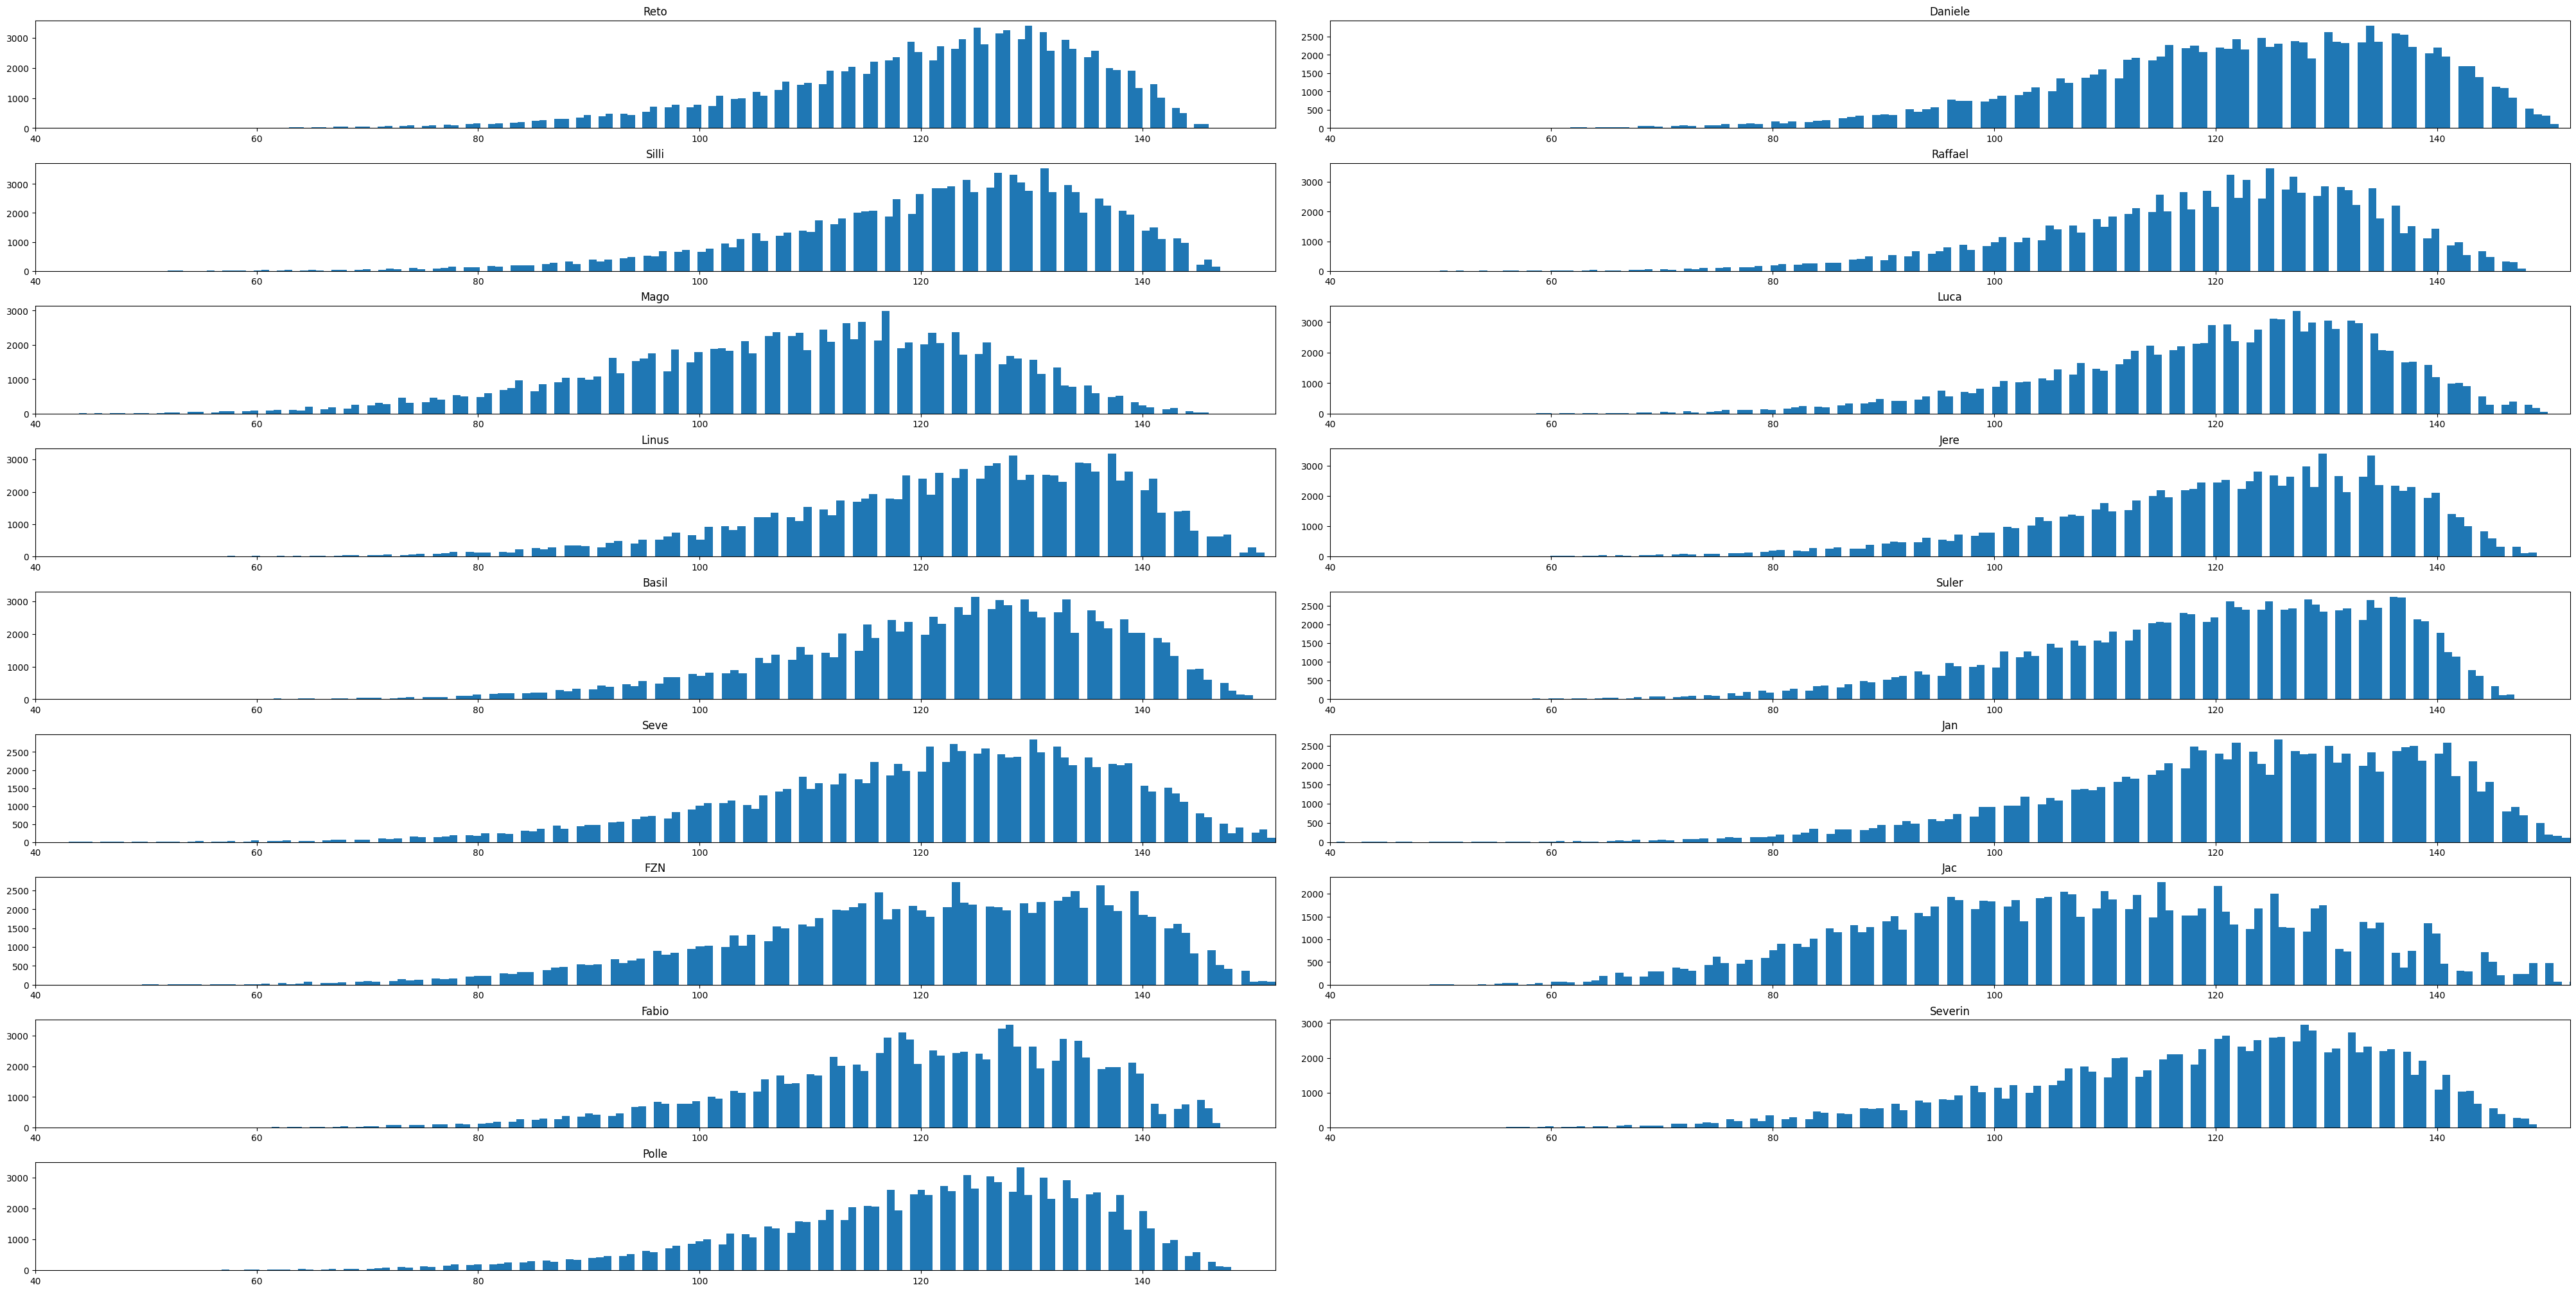

In [8]:
simulate_bets(BETS, get_schedule, sims, odds=get_sb_odds())

In [9]:
# First game is played SEA@SF : SEA 25 : 41 SF
def schedule(schedule_):
    for matchup in schedule_.afc_r1:
        if matchup.home.name == "HOU":
            matchup.odds_away = 0
            matchup.odds_home = 1
    return schedule_

Team	Mean	Median	std	max	min	q60	q80
*****	*****	*****	*****	*****	*****	*****	*****
Reto	130.9	133.0	8.7	144	58	135.0	138.0
Daniele	125.63	129.0	12.4	145	44	132.0	136.0
Silli	130.67	132.0	9.46	143	53	134.0	139.0
Raffael	128.77	131.0	10.75	146	56	133.0	138.0
Mago	122.33	123.0	10.93	146	57	127.0	132.0
Luca	129.74	131.0	10.83	150	36	134.0	139.0


KeyboardInterrupt: 

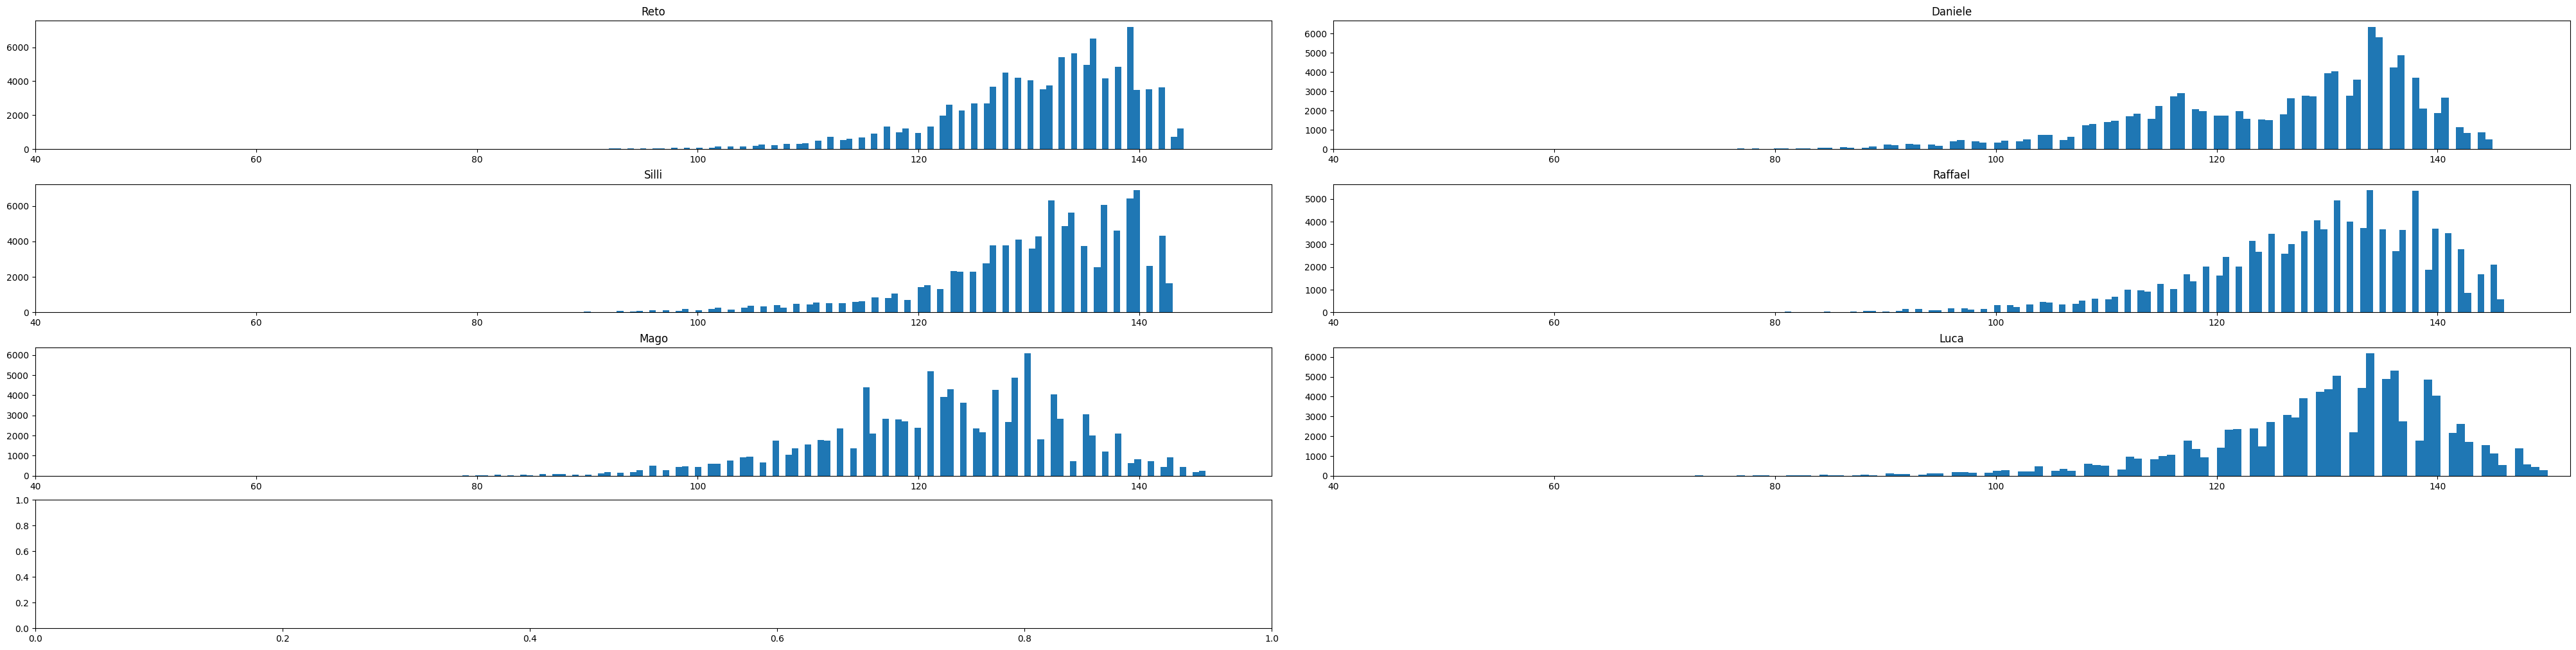

In [10]:
simulate_bets(BETS, get_schedule, sims, schedule_adjuster=schedule)

In [ ]:
simulate_bets(BETS, get_schedule, sims, odds=get_sb_odds(), schedule_adjuster=schedule)

In [ ]:
# First game is played SEA@SF : SEA 25 : 41 SF
def schedule(schedule_):
    for matchup in schedule_.afc_r1:
        if matchup.home.name == "HOU" or matchup.home.name == "BAL":
            matchup.odds_away = 0
            matchup.odds_home = 1
    return schedule_

In [ ]:
simulate_bets(BETS, get_schedule, sims, schedule_adjuster=schedule)

In [ ]:
simulate_bets(BETS, get_schedule, sims, odds=get_sb_odds(), schedule_adjuster=schedule)

In [13]:
# First game is played SEA@SF : SEA 25 : 41 SF
def schedule(schedule_):
    for matchup in schedule_.afc_r1:
        if matchup.home.name == "HOU" or matchup.home.name == "BAL" or matchup.home.name == "BUF":
            matchup.odds_away = 0
            matchup.odds_home = 1
    return schedule_

In [15]:
sims = 10000

Team	Mean	Median	std	max	min	q60	q80
*****	*****	*****	*****	*****	*****	*****	*****
Reto	132.85	134.0	7.08	144	89	136.0	139.0
Daniele	127.05	131.0	11.74	145	68	134.0	137.0
Silli	132.51	134.0	8.21	143	82	136.0	139.0
Raffael	130.27	132.0	9.75	146	75	134.0	138.0
Mago	123.71	124.0	10.46	146	68	128.0	132.0
Luca	131.45	133.0	9.61	150	82	135.0	139.0
Linus	133.23	135.0	9.49	149	87	137.0	141.0
Jere	133.44	135.0	10.19	149	81	138.0	142.0
Basil	134.98	138.0	10.51	150	83	140.0	143.0
Suler	129.62	133.0	12.22	147	74	136.0	140.0
Seve	128.96	131.0	10.34	147	74	133.0	138.0
Jan	133.82	138.0	12.13	152	82	141.0	143.0
FZN	131.16	136.0	13.12	152	80	139.0	142.0
Jac	101.64	99.0	16.18	150	65	104.0	115.0
Fabio	131.44	134.0	10.41	147	76	135.0	140.0
Severin	130.23	134.0	13.04	149	66	136.0	141.0
Polle	131.05	133.0	7.95	143	86	135.0	138.0


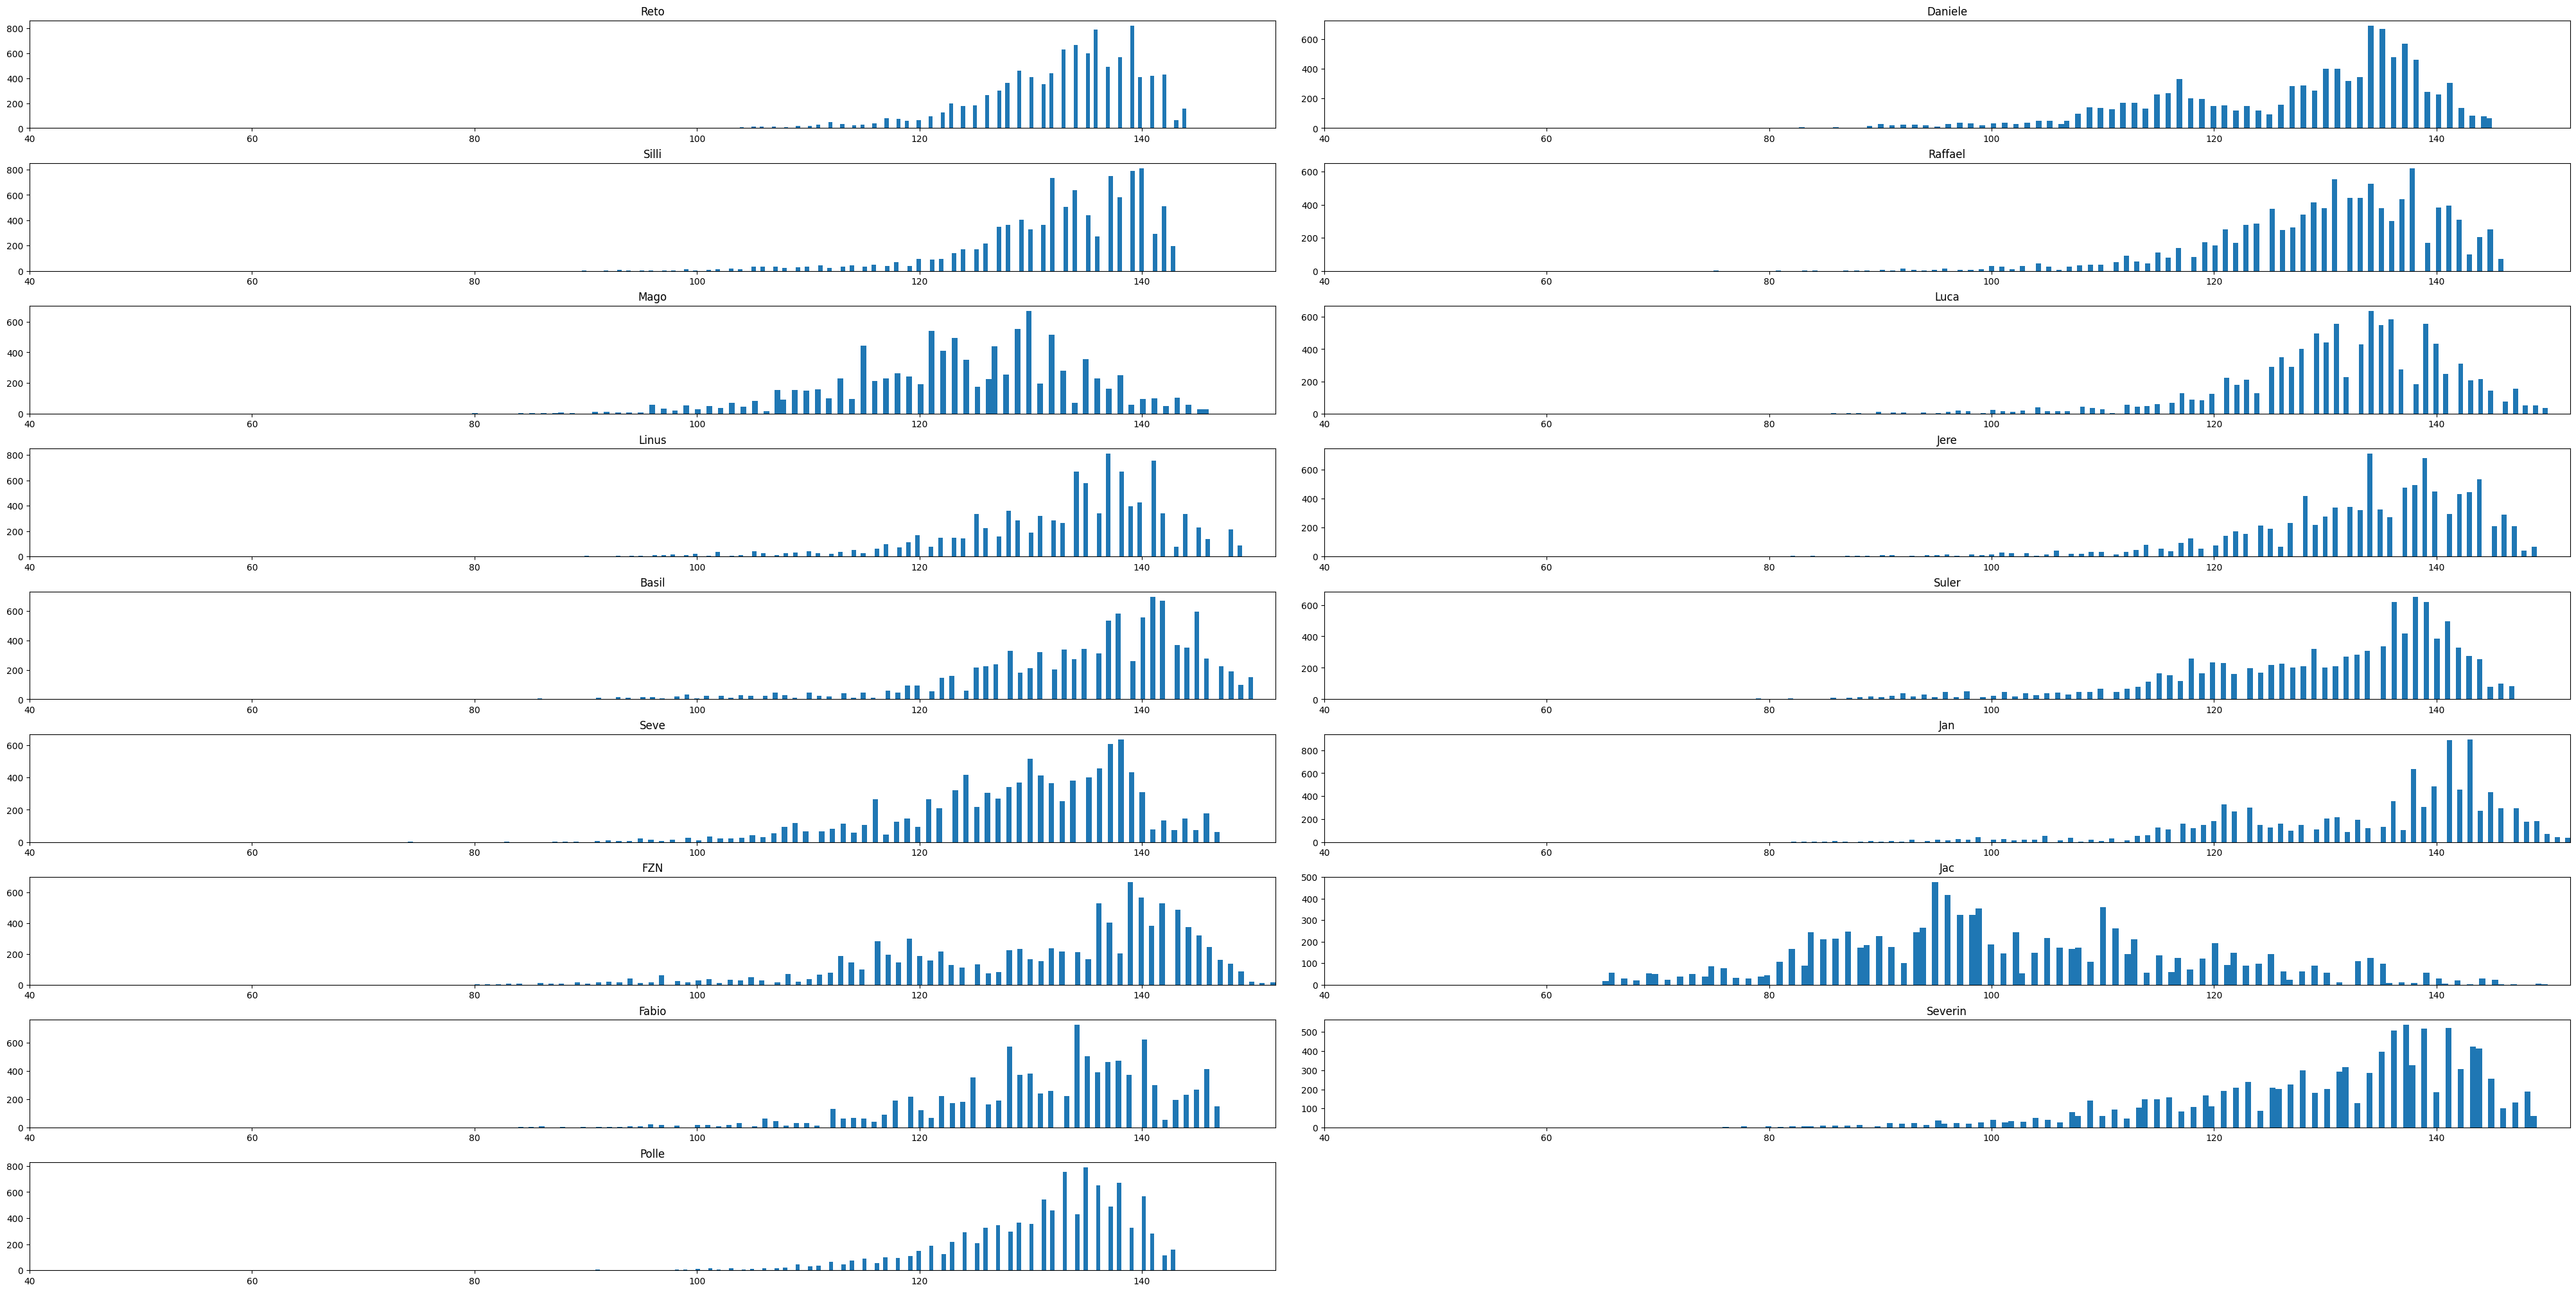

In [16]:
simulate_bets(BETS, get_schedule, sims, schedule_adjuster=schedule)

Team	Mean	Median	std	max	min	q60	q80
*****	*****	*****	*****	*****	*****	*****	*****
Reto	125.36	127.0	10.78	144	81	129.0	135.0
Daniele	121.91	124.0	13.79	145	67	128.0	134.0
Silli	123.8	125.0	11.71	143	75	128.0	134.0
Raffael	121.78	124.0	13.27	146	72	127.0	133.0
Mago	115.5	117.0	14.13	146	68	121.0	129.0
Luca	125.75	127.0	12.03	150	76	130.0	136.0
Linus	127.75	129.0	11.49	149	77	132.0	137.0
Jere	127.89	130.0	12.1	149	73	133.0	138.0
Basil	129.41	131.0	11.61	150	81	134.0	140.0
Suler	123.91	126.0	14.05	147	71	130.0	137.0
Seve	122.41	125.0	13.79	147	65	128.0	134.0
Jan	131.03	133.0	13.01	152	82	138.0	143.0
FZN	127.87	130.0	14.09	152	75	134.0	141.0
Jac	109.63	110.0	17.48	150	65	115.0	126.0
Fabio	124.66	126.0	12.84	147	75	129.0	136.0
Severin	122.94	126.0	15.05	149	65	129.0	136.0
Polle	121.61	124.0	12.96	143	72	127.0	133.0


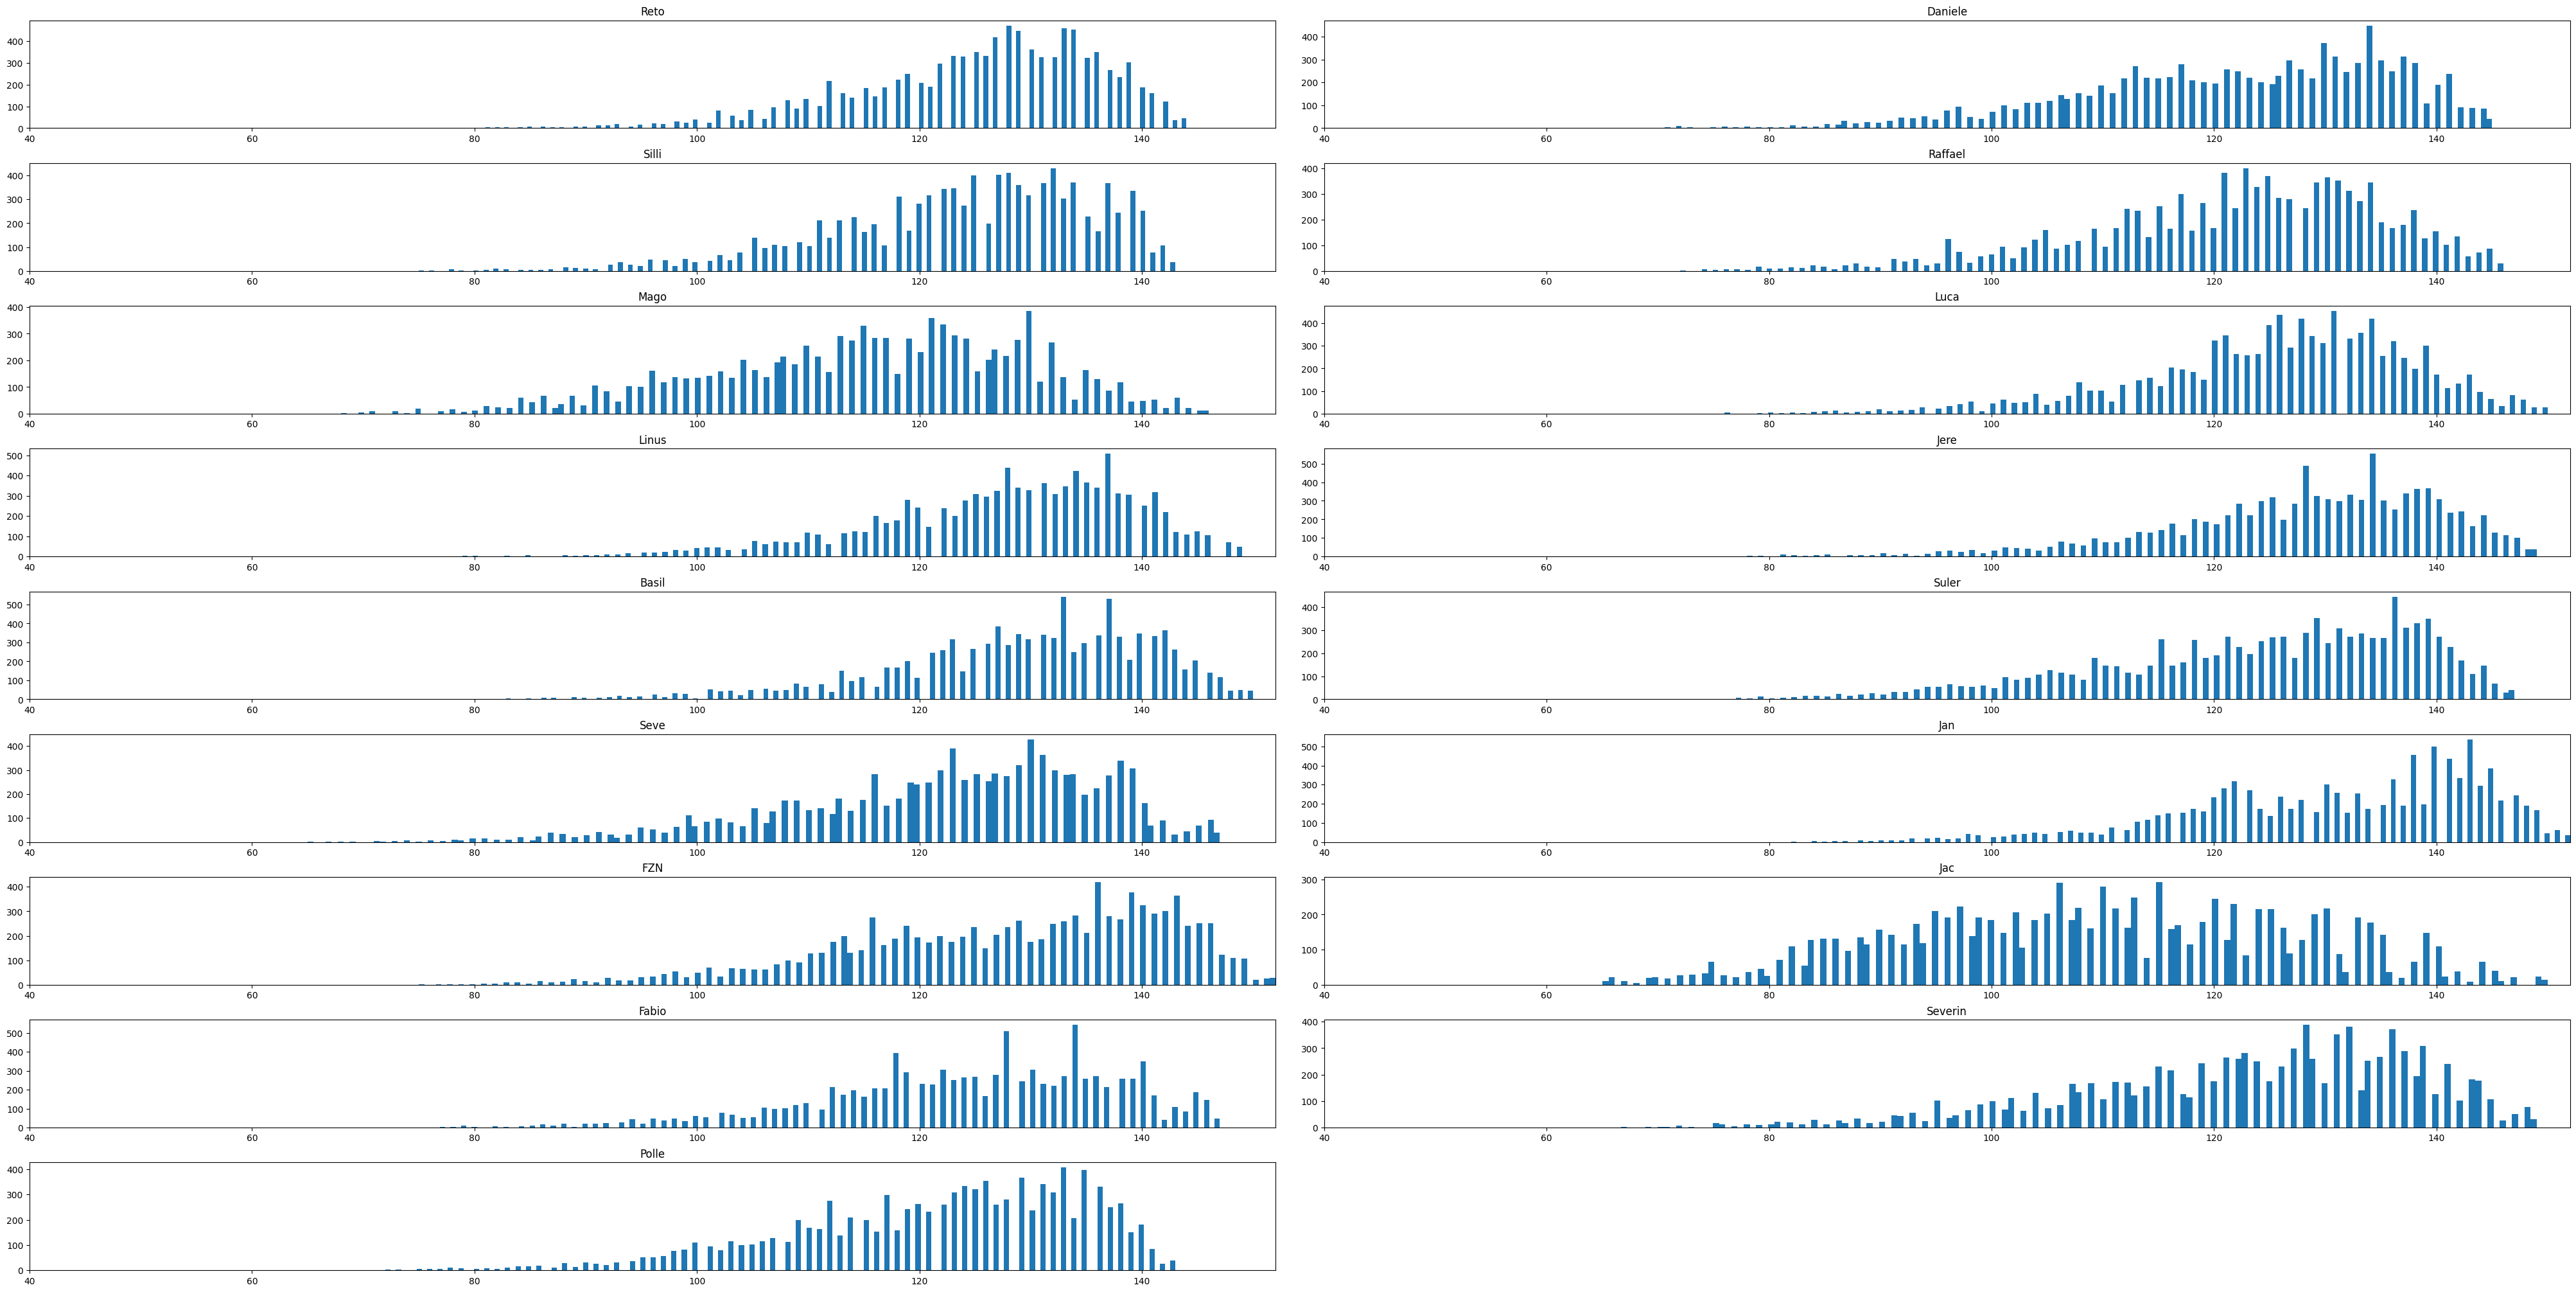

In [17]:
simulate_bets(BETS, get_schedule, sims, odds=get_sb_odds(), schedule_adjuster=schedule)